In [3]:
# EN: Install dependencies so the notebook runs after a session restart
# PT: Instala dependências para o notebook rodar após reiniciar a sessão
%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [4]:
"""Synthetic attendance data generator / Gerador de dados sintéticos de frequência."""
from __future__ import annotations

import numpy as np
import pandas as pd

SEED = 42  # EN: fixed seed = same data every run / PT: seed fixa = mesmos dados sempre
DEPARTMENTS = ["Administrativo", "TI", "Financeiro", "RH", "Logística", "Atendimento"]
FIRST_NAMES = ["Ana", "Bruno", "Carla", "Diego", "Elisa", "Felipe", "Gabriela", "Hugo"]
LAST_NAMES = ["Alves", "Barros", "Costa", "Dias", "Ferraz", "Gomes", "Lima", "Moraes"]
STATUS = ["Presente", "Atraso", "Falta", "Atestado"]
BASE_PROBS = [0.90, 0.04, 0.03, 0.03]


def create_employees(n: int, rng: np.random.Generator) -> pd.DataFrame:
    """Create fictional employees / Cria funcionários fictícios."""
    # EN: each employee has a personal absence tendency
    # PT: cada funcionário tem uma tendência pessoal de faltar
    return pd.DataFrame(
        {
            "employee_id": [f"F{i:03d}" for i in range(1, n + 1)],
            "name": [
                f"{rng.choice(FIRST_NAMES)} {rng.choice(LAST_NAMES)}" for _ in range(n)
            ],
            "department": rng.choice(DEPARTMENTS, size=n),
            "absence_factor": rng.uniform(0.5, 2.0, size=n),
        }
    )


def create_attendance(
    employees: pd.DataFrame, start: str, end: str, rng: np.random.Generator
) -> pd.DataFrame:
    """Create daily attendance records / Cria registros diários de frequência."""
    # EN: business days only / PT: apenas dias úteis
    days = pd.bdate_range(start, end)
    rows = []
    for emp in employees.itertuples():
        # EN: scale non-present probabilities by the employee's factor
        # PT: escala as probabilidades de não presença pelo fator do funcionário
        bad = np.array(BASE_PROBS[1:]) * emp.absence_factor
        probs = np.concatenate([[1 - bad.sum()], bad])
        status = rng.choice(STATUS, size=len(days), p=probs)
        minutes_late = np.where(status == "Atraso", rng.integers(5, 61, len(days)), 0)
        rows.append(
            pd.DataFrame(
                {
                    "employee_id": emp.employee_id,
                    "date": days,
                    "status": status,
                    "minutes_late": minutes_late,
                }
            )
        )
    return pd.concat(rows, ignore_index=True)


def generate_dataset(n_employees: int = 50) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return (employees, attendance) / Retorna (funcionários, frequência)."""
    rng = np.random.default_rng(SEED)
    employees = create_employees(n_employees, rng).drop(columns="absence_factor")
    # EN: recreate with the factor to build attendance, then drop it
    # PT: recria com o fator para gerar a frequência e depois remove
    rng = np.random.default_rng(SEED)
    full = create_employees(n_employees, rng)
    attendance = create_attendance(full, "2025-01-01", "2025-12-31", rng)
    return employees, attendance

In [5]:
import matplotlib.pyplot as plt

# EN: Build one table with everything / PT: Monta uma tabela única com tudo
employees, attendance = generate_dataset()
df = attendance.merge(employees, on="employee_id", how="left")
df["month"] = df["date"].dt.month

# EN: Absence = unjustified absence or medical certificate
# PT: Ausência = falta ou atestado
df["is_absent"] = df["status"].isin(["Falta", "Atestado"])

overall_rate = df["is_absent"].mean() * 100
print(f"Taxa de absenteísmo geral / Overall absenteeism rate: {overall_rate:.2f}%")

Taxa de absenteísmo geral / Overall absenteeism rate: 7.10%


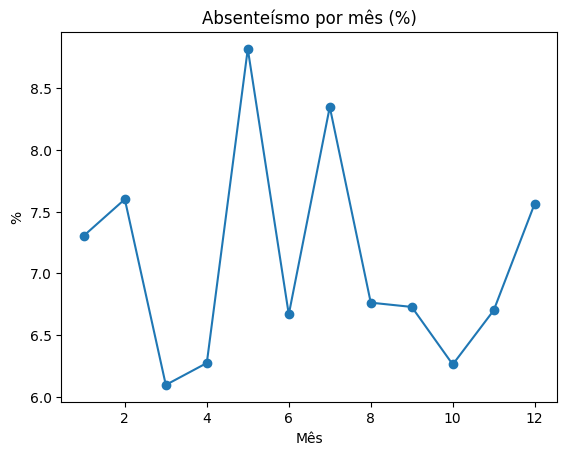

In [6]:
def plot_monthly_rate(data) -> None:
    """Absenteeism rate by month / Taxa de absenteísmo por mês."""
    rate = data.groupby("month")["is_absent"].mean() * 100
    rate.plot(kind="line", marker="o", title="Absenteísmo por mês (%)")
    plt.xlabel("Mês"); plt.ylabel("%"); plt.show()

plot_monthly_rate(df)

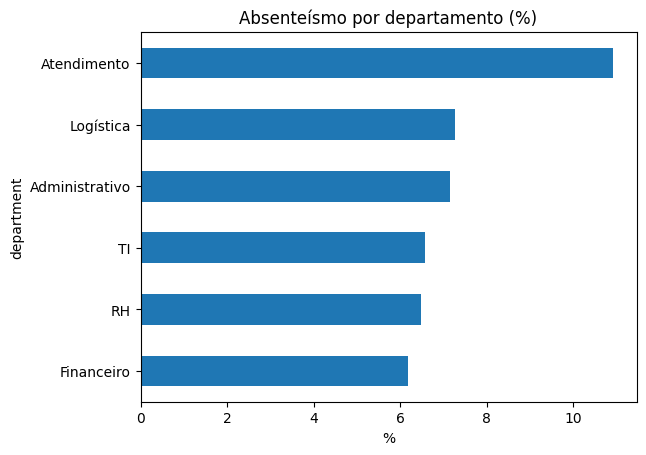

In [7]:
def plot_department_rate(data) -> None:
    """Absenteeism rate by department / Taxa de absenteísmo por departamento."""
    rate = data.groupby("department")["is_absent"].mean().sort_values() * 100
    rate.plot(kind="barh", title="Absenteísmo por departamento (%)")
    plt.xlabel("%"); plt.show()

plot_department_rate(df)

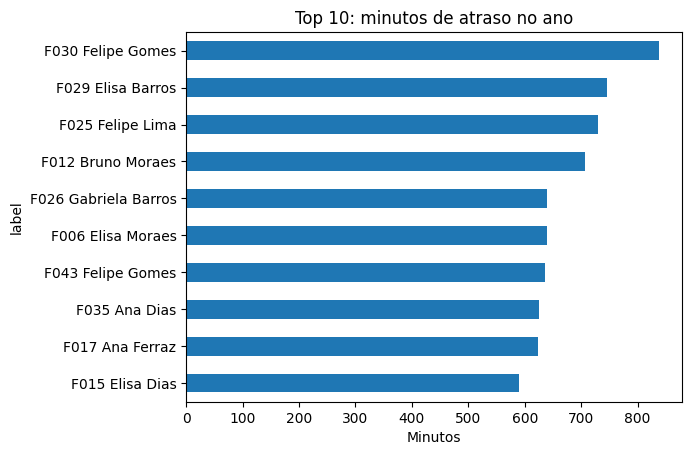

In [8]:
def plot_top_late(data) -> None:
    """Top 10 by total minutes late / Top 10 por minutos de atraso."""
    # EN: names can repeat, so the label uses ID + name
    # PT: nomes podem se repetir, então o rótulo usa ID + nome
    data = data.assign(label=data["employee_id"] + " " + data["name"])
    top = data.groupby("label")["minutes_late"].sum().nlargest(10).sort_values()
    top.plot(kind="barh", title="Top 10: minutos de atraso no ano")
    plt.xlabel("Minutos"); plt.show()

plot_top_late(df)

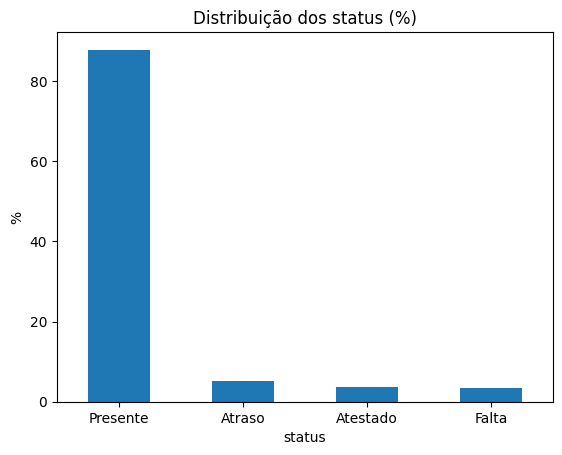

In [9]:
def plot_status_share(data) -> None:
    """Share of each status / Participação de cada status."""
    share = data["status"].value_counts(normalize=True) * 100
    share.plot(kind="bar", title="Distribuição dos status (%)", rot=0)
    plt.ylabel("%"); plt.show()

plot_status_share(df)

In [16]:
# EN: Key results to use in the conclusions and README
# PT: Resultados principais para as conclusões e o README
monthly = df.groupby("month")["is_absent"].mean() * 100
by_dept = df.groupby("department")["is_absent"].mean() * 100
late = (
    df.assign(label=df["employee_id"] + " " + df["name"])
    .groupby("label")["minutes_late"].sum()
)

print(f"Taxa geral: {overall_rate:.2f}%")
print(f"Mês mais alto: {monthly.idxmax()} ({monthly.max():.2f}%)")
print(f"Mês mais baixo: {monthly.idxmin()} ({monthly.min():.2f}%)")
print(f"Depto mais alto: {by_dept.idxmax()} ({by_dept.max():.2f}%)")
print(f"Depto mais baixo: {by_dept.idxmin()} ({by_dept.min():.2f}%)")
print(f"Mais atrasos: {late.idxmax()} ({late.max()} min)")

Taxa geral: 7.10%
Mês mais alto: 5 (8.82%)
Mês mais baixo: 3 (6.10%)
Depto mais alto: Atendimento (10.92%)
Depto mais baixo: Financeiro (6.19%)
Mais atrasos: F030 Felipe Gomes (837 min)


## Conclusões / Conclusions

**PT**
- Taxa de absenteísmo geral (faltas + atestados): **7,10%**.
- Maior taxa mensal: **maio (8,82%)**. Menor: **março (6,10%)**.
- Maior taxa por departamento: **Atendimento (10,92%)**. Menor: **Financeiro (6,19%)**.
- Mais minutos de atraso no ano: **F030 Felipe Gomes (837 min)**.
- **Atenção:** os dados são sintéticos (seed 42). As diferenças entre meses e departamentos vêm do sorteio aleatório, não de causas reais. O objetivo é demonstrar o método de análise.

**EN**
- Overall absenteeism rate (absences + medical certificates): **7.10%**.
- Highest monthly rate: **May (8.82%)**. Lowest: **March (6.10%)**.
- Highest rate by department: **Customer Service (10.92%)**. Lowest: **Finance (6.19%)**.
- Most minutes late in the year: **F030 Felipe Gomes (837 min)**.
- **Note:** the data is synthetic (seed 42). Differences between months and departments come from random generation, not real causes. The goal is to demonstrate the analysis method.